# Laboratório: Consumindo uma API de Cotação de Moedas com Python 💱

**Disciplina:** Laboratório de Programação — Ciência da Computação (UFPI)  
**Prof.:** Armando Soares Sousa — Departamento de Computação

---

## 🎯 Objetivos da atividade

Ao final deste laboratório você será capaz de:

1. Explicar o que é uma **API web** e o que é um **endpoint**.
2. Ler a **documentação** de uma API e montar as URLs corretas.
3. Fazer requisições com **`requests`** e converter respostas **JSON** em dicionários e listas do Python.
4. **Navegar** em estruturas aninhadas (dicionário dentro de dicionário, lista de dicionários).
5. **Converter tipos**: textos em números e *timestamps* em datas.
6. **Tratar erros**: moeda inexistente, falta de internet, limite de requisições.
7. Transformar os dados em uma **tabela do Pandas** e fazer um **gráfico** do histórico.
8. Construir um pequeno **conversor de moedas**.

## 🗺️ Roteiro sugerido (≈ 100 minutos)

| Parte | Conteúdo | Tempo |
|---|---|---|
| 0 | Preparação do ambiente | 5 min |
| 1 | O que é uma API? Conhecendo a AwesomeAPI | 10 min |
| 2 | Primeira requisição: o endpoint principal | 10 min |
| 3 | A cotação de uma moeda | 15 min |
| 4 | Várias moedas de uma vez | 15 min |
| 5 | Quando algo dá errado | 10 min |
| 6 | Histórico de cotações e gráfico | 20 min |
| 7 | Mini-projeto: conversor de moedas | 15 min |
| 8 | Exercícios | livre |

## 🧭 Como usar este notebook

- Execute as células **na ordem** (`Shift + Enter`).
- **Leia o texto antes de executar** e tente **prever o resultado**.
- Blocos **🤔 Pare e pense** são para discussão com a turma.
- Blocos **✍️ Sua vez** têm células vazias para você escrever código.
- Este notebook **precisa de internet**. As cotações mudam ao longo do dia, então seus números serão diferentes dos de um colega que executou em outro momento.

---
# Parte 0 — Preparação do ambiente

In [47]:
import json                      # exibir JSON de forma organizada
from datetime import datetime, timezone
from zoneinfo import ZoneInfo    # fusos horários (Python 3.9+)

import requests
import pandas as pd
import matplotlib.pyplot as plt

print("requests:", requests.__version__, "| pandas:", pd.__version__)

requests: 2.32.4 | pandas: 2.2.3


Vamos guardar o endereço base do serviço em uma **constante** (por convenção, nomes em MAIÚSCULAS):

In [48]:
BASE_URL = "https://economia.awesomeapi.com.br"
TIMEOUT = 10   # segundos de espera máxima por resposta

---
# Parte 1 — O que é uma API? Conhecendo a AwesomeAPI

## 1.1 API: um "garçom" entre programas

Uma **API** (*Application Programming Interface*) é uma forma de um programa **pedir dados ou serviços** a outro programa.

Pense em um restaurante:

| Restaurante | API web |
|---|---|
| Você (cliente) | o seu programa Python |
| O cardápio | a **documentação** da API |
| O garçom | a **API**: recebe o pedido e traz a resposta |
| A cozinha | o **servidor** com os dados |
| O prato | a **resposta**, geralmente em **JSON** |

Você não precisa saber **como** a cozinha funciona — só precisa saber **pedir** do jeito certo (o que está no cardápio).

## 1.2 Endpoints: os "pratos do cardápio"

Cada endereço que a API oferece se chama **endpoint**. A AwesomeAPI (documentação: https://docs.awesomeapi.com.br/api-de-moedas) tem, entre outros:

| Endpoint | O que devolve |
|---|---|
| `/` | informações gerais sobre a API |
| `/json/last/:moedas` | a **cotação mais recente** de uma ou mais moedas |
| `/json/daily/:moeda/:numero_dias` | o **fechamento** dos últimos dias (máximo 360) |
| `/json/daily/:moeda/:numero_dias?start_date=AAAAMMDD&end_date=AAAAMMDD` | o fechamento em um **período** |

> 💡 Na documentação, `:moedas` indica uma **parte variável** da URL. Ela deve ser trocada por um valor real, como `USD-BRL`.

## 1.3 Os códigos das moedas

Os pares de moedas seguem o formato **`ORIGEM-DESTINO`**, usando códigos internacionais (padrão ISO 4217):

| Código | Moeda | | Código | Moeda |
|---|---|---|---|---|
| `BRL` | Real brasileiro | | `GBP` | Libra esterlina |
| `USD` | Dólar americano | | `JPY` | Iene japonês |
| `EUR` | Euro | | `ARS` | Peso argentino |
| `BTC` | Bitcoin (criptomoeda) | | `CNY` | Yuan chinês |

Exemplo: `USD-BRL` = **quantos reais vale 1 dólar**.

A lista completa de combinações está em: https://economia.awesomeapi.com.br/xml/available

## 1.4 Limites de uso ⚠️

APIs públicas costumam ter **limites** para não sobrecarregar o servidor. Segundo a documentação da AwesomeAPI:

- **sem chave de API:** as respostas ficam em **cache por 1 minuto** (pedir de novo em poucos segundos devolve o mesmo valor);
- **com chave de API** (cadastro gratuito): até **100 mil requisições por mês**, sem cache.

> 🤔 **Pare e pense:** em um laboratório, todos os computadores podem sair para a internet pelo **mesmo endereço IP**. Para o servidor, parece que **um único usuário** está fazendo dezenas de pedidos ao mesmo tempo. O que pode acontecer? (Veremos na Parte 5.)

---
# Parte 2 — Primeira requisição: o endpoint principal

In [49]:
from google.colab import userdata
# Crie sua conta no https://awesomeapi.com.br
# crie sua chave de acesso via secrets do Google Colabs
try:
  MY_API_KEY = userdata.get('AWESOME_API')
  print("MY_API_KEY carregada com sucesso!")
except Exception as ex:
  print(f"Erro ao carregar a chave de acesso! - {str(ex)}")

MY_API_KEY carregada com sucesso!


In [50]:
print(f"URL: {BASE_URL}")
TOKEN = f"?token={MY_API_KEY}"
resposta = requests.get(BASE_URL + "/" + TOKEN, timeout=TIMEOUT)

print("Status:", resposta.status_code, resposta.reason)
print("Tipo do conteúdo:", resposta.headers.get("Content-Type"))

URL: https://economia.awesomeapi.com.br
Status: 200 OK
Tipo do conteúdo: application/json; charset=utf-8


A resposta está em **JSON**. O método `.json()` converte o texto em objetos Python (dicionários, listas, textos, números):

In [51]:
dados = resposta.json()
print(type(dados))
dados

<class 'dict'>


{'info': {'title': 'API de Cotações',
  'api_docs': 'https://docs.awesomeapi.com.br/api-de-moedas',
  'contact': 'contato@awesomeapi.com.br'},
 'labels': {'bid': 'Compra',
  'ask': 'Venda',
  'varBid': 'Variação',
  'pctChange': 'Porcentagem de Variação',
  'high': 'Máximo',
  'low': 'Mínimo'}}

Para ler JSON com mais conforto, podemos usar `json.dumps` com **indentação**.
O `ensure_ascii=False` mantém os acentos legíveis (em vez de `\u00e7`):

In [52]:
print(json.dumps(dados, indent=2, ensure_ascii=False))

{
  "info": {
    "title": "API de Cotações",
    "api_docs": "https://docs.awesomeapi.com.br/api-de-moedas",
    "contact": "contato@awesomeapi.com.br"
  },
  "labels": {
    "bid": "Compra",
    "ask": "Venda",
    "varBid": "Variação",
    "pctChange": "Porcentagem de Variação",
    "high": "Máximo",
    "low": "Mínimo"
  }
}


### JSON × Python

| JSON | Python |
|---|---|
| `{ "chave": valor }` (objeto) | `dict` |
| `[ 1, 2, 3 ]` (array) | `list` |
| `"texto"` | `str` |
| `10`, `3.14` | `int`, `float` |
| `true` / `false` | `True` / `False` |
| `null` | `None` |

### Navegando no dicionário

`dados` é um dicionário com duas chaves: `info` e `labels`. Cada uma guarda **outro dicionário** (estrutura **aninhada**).
Para descer um nível, encadeamos colchetes:

In [53]:
print("Chaves do primeiro nível:", list(dados.keys()))
print()
print("Título:      ", dados["info"]["title"])
print("Documentação:", dados["info"]["api_docs"])

Chaves do primeiro nível: ['info', 'labels']

Título:       API de Cotações
Documentação: https://docs.awesomeapi.com.br/api-de-moedas


A chave `labels` é uma espécie de **legenda** dos campos que aparecerão nas cotações. Vamos percorrê-la com um laço:

In [54]:
for campo, significado in dados["labels"].items():
    print(f"{campo:<10} → {significado}")

bid        → Compra
ask        → Venda
varBid     → Variação
pctChange  → Porcentagem de Variação
high       → Máximo
low        → Mínimo


> 💡 `.items()` devolve pares **(chave, valor)**. Com `for campo, significado in ...` já separamos os dois em variáveis — isso se chama **desempacotamento**.

---
# Parte 3 — A cotação de uma moeda

## 3.1 Montando a URL e fazendo o pedido

In [56]:
par = "USD-BRL"
url = f"{BASE_URL}/json/last/{par}" + TOKEN

print(f"Aguarde...")
resposta = requests.get(url, timeout=TIMEOUT)
resposta.raise_for_status()      # lança exceção se o status for 4xx ou 5xx
cotacao_dolar = resposta.json()

print(json.dumps(cotacao_dolar, indent=2, ensure_ascii=False))

Aguarde...
{
  "USDBRL": {
    "code": "USD",
    "codein": "BRL",
    "name": "Dólar Americano/Real Brasileiro",
    "high": "5.0543",
    "low": "4.9636",
    "varBid": "-0.0871",
    "pctChange": "-1.723967",
    "bid": "4.9652",
    "ask": "4.966",
    "timestamp": "1792791008",
    "create_date": "2026-10-23 18:30:08"
  }
}


## 3.2 Entendendo a estrutura

```
{
  "USDBRL": {             ← chave = par de moedas SEM o hífen
    "code": "USD",        ← moeda de origem
    "codein": "BRL",      ← moeda de destino
    "bid": "5.4427",      ← valor de COMPRA
    "ask": "5.4433",      ← valor de VENDA
    ...
  }
}
```

| Campo | Significado |
|---|---|
| `bid` | **compra**: quanto o mercado paga por 1 unidade da moeda |
| `ask` | **venda**: quanto o mercado cobra por 1 unidade da moeda |
| `high` / `low` | maior / menor valor do dia |
| `varBid` | variação do valor de compra no dia |
| `pctChange` | variação percentual no dia |
| `timestamp` | momento da cotação em segundos desde 01/01/1970 (UTC) |
| `create_date` | data e hora da cotação (horário de Brasília) |

> 💡 Repare que a chave é `"USDBRL"`, **sem hífen**, mesmo tendo pedido `"USD-BRL"`. Para não errar, podemos montar a chave com `par.replace("-", "")`.

In [57]:
chave = par.replace("-", "")
dolar = cotacao_dolar[chave]

print("Moeda:  ", dolar["name"])
print("Compra: ", dolar["bid"])
print("Venda:  ", dolar["ask"])
print("Data:   ", dolar["create_date"])

Moeda:   Dólar Americano/Real Brasileiro
Compra:  4.9652
Venda:   4.966
Data:    2026-10-23 18:30:08


## 3.3 Atenção: os números chegam como **texto**! ⚠️

In [58]:
print(type(dolar["bid"]))
print("Somando textos:", dolar["bid"] + dolar["ask"])   # concatena, não soma!

<class 'str'>
Somando textos: 4.96524.966


O operador `+` com textos **junta** os textos. Para fazer contas, precisamos **converter** com `float()`:

In [59]:
compra = float(dolar["bid"])
venda = float(dolar["ask"])
spread = venda - compra          # diferença entre venda e compra

print(f"Compra: R$ {compra:.4f}")
print(f"Venda:  R$ {venda:.4f}")
print(f"Spread: R$ {spread:.4f}  ({spread / compra * 100:.3f}% do valor de compra)")

Compra: R$ 4.9652
Venda:  R$ 4.9660
Spread: R$ 0.0008  (0.016% do valor de compra)


> 🤔 **Pare e pense:** o **spread** é a diferença entre o preço de venda e o de compra. Quem fica com essa diferença? Por que casas de câmbio costumam ter spreads **bem maiores** do que esse?

## 3.4 Convertendo o *timestamp* em data

O `timestamp` é o número de **segundos desde 1º de janeiro de 1970, 00:00 UTC** (a chamada "Era Unix"). É assim que muitos sistemas guardam datas internamente.

In [60]:
ts = int(dolar["timestamp"])
print("timestamp:", ts)

momento_utc = datetime.fromtimestamp(ts, tz=timezone.utc)
momento_brasilia = momento_utc.astimezone(ZoneInfo("America/Sao_Paulo"))

print("UTC:     ", momento_utc.strftime("%d/%m/%Y %H:%M:%S"))
print("Brasília:", momento_brasilia.strftime("%d/%m/%Y %H:%M:%S"))
print("create_date da API:", dolar["create_date"])

timestamp: 1792791008
UTC:      23/10/2026 21:30:08
Brasília: 23/10/2026 18:30:08
create_date da API: 2026-10-23 18:30:08


> 💡 Códigos do `strftime`: `%d` dia, `%m` mês, `%Y` ano com 4 dígitos, `%H` hora, `%M` minuto, `%S` segundo.

### ✍️ Sua vez

Busque a cotação do **Euro** (`EUR-BRL`) e mostre: o nome, o valor de compra como número e a variação percentual do dia (`pctChange`).

In [ ]:
# Sua vez

---
# Parte 4 — Várias moedas de uma vez

## 4.1 Uma única requisição para vários pares

A documentação diz que podemos pedir várias moedas **separadas por vírgula**. Uma requisição só é mais **rápida** e **economiza** o limite de uso.

Uma forma organizada: guardar os pares em uma **lista** e juntá-los com `",".join(...)`:

In [61]:
pares = ["USD-BRL", "EUR-BRL", "BTC-BRL"]
url = f"{BASE_URL}/json/last/{','.join(pares)}" + TOKEN

print(f"Aguarde...")
resposta = requests.get(url, timeout=TIMEOUT)
resposta.raise_for_status()
cotacoes = resposta.json()

print("Chaves recebidas:", list(cotacoes.keys()))

Aguarde...
Chaves recebidas: ['USDBRL', 'EURBRL', 'BTCBRL']


## 4.2 Percorrendo o resultado

Compare duas formas de escrever o mesmo laço:

```python
# Forma 1: acessando pelos índices da tupla (menos legível)
for item in cotacoes.items():
    moeda = item[0]
    valor = item[1]["bid"]

# Forma 2: desempacotando a tupla (mais legível) ✅
for moeda, info in cotacoes.items():
    valor = info["bid"]
```

In [62]:
print(f"{'Par':<8} {'Nome':<34} {'Compra':>14} {'Var. dia':>9}  Data")
print("-" * 82)
for chave, info in cotacoes.items():
    compra = float(info["bid"])
    variacao = float(info["pctChange"])
    print(f"{chave:<8} {info['name']:<34} {compra:>14,.4f} {variacao:>8.2f}%  {info['create_date']}")

Par      Nome                                       Compra  Var. dia  Data
----------------------------------------------------------------------------------
USDBRL   Dólar Americano/Real Brasileiro            4.9652    -1.72%  2026-10-23 18:30:08
EURBRL   Euro/Real Brasileiro                       5.5617    -1.87%  2026-10-23 18:29:29
BTCBRL   Bitcoin/Real Brasileiro              405,455.0000    -1.48%  2026-10-23 19:47:15


> 💡 Na formatação `{valor:>14,.4f}`: `>` alinha à direita, `14` é a largura, `,` separa milhares e `.4f` mostra 4 casas decimais.

## 4.3 De dicionário para tabela (Pandas)

Um dicionário de dicionários vira facilmente uma tabela: cada chave externa vira uma **linha**.

In [63]:
df_cotacoes = pd.DataFrame.from_dict(cotacoes, orient="index")
df_cotacoes

,code,codein,name,high,low,varBid,pctChange,bid,ask,timestamp,create_date
USDBRL,USD,BRL,Dólar Americano/Real Brasileiro,5.0543,4.9636,-0.0871,-1.723967,4.9652,4.966,1792791008,2026-10-23 18:30:08
EURBRL,EUR,BRL,Euro/Real Brasileiro,5.6703,5.5617,-0.1061,-1.871978,5.5617,5.5637,1792790969,2026-10-23 18:29:29
BTCBRL,BTC,BRL,Bitcoin/Real Brasileiro,414879,405100,-6088,-1.479,405455,405456,1792795635,2026-10-23 19:47:15


As colunas numéricas ainda são texto. Vamos convertê-las de uma vez com `astype(float)`:

In [64]:
colunas_numericas = ["high", "low", "varBid", "pctChange", "bid", "ask"]
df_cotacoes[colunas_numericas] = df_cotacoes[colunas_numericas].astype(float)

df_cotacoes["spread_pct"] = (df_cotacoes["ask"] - df_cotacoes["bid"]) / df_cotacoes["bid"] * 100

df_cotacoes[["name", "bid", "ask", "pctChange", "spread_pct"]]

,name,bid,ask,pctChange,spread_pct
USDBRL,Dólar Americano/Real Brasileiro,4.9652,4.9660,-1.723967,0.016112
EURBRL,Euro/Real Brasileiro,5.5617,5.5637,-1.871978,0.035960
BTCBRL,Bitcoin/Real Brasileiro,405455.0000,405456.0000,-1.479000,0.000247


> 🤔 **Pare e pense:** qual dos três pares tem o maior spread percentual? Por que isso pode acontecer com uma criptomoeda?

---
# Parte 5 — Quando algo dá errado

## 5.1 Moeda inexistente

O que acontece se pedirmos um par que não existe? A documentação diz que a API responde com status **404** e um JSON explicando o erro:

In [65]:
print(f"Aguarde...")
resposta = requests.get(f"{BASE_URL}/json/last/ABC-BRL{TOKEN}", timeout=TIMEOUT)

print("Status:", resposta.status_code)
print("Corpo :", resposta.text)

Aguarde...
Status: 404
Corpo : {"status":404,"code":"CoinNotExists","message":"moeda nao encontrada ABC-BRL"}


> 💡 Mesmo com erro, o **corpo** da resposta traz uma mensagem útil. Vale a pena mostrá-la ao usuário.

## 5.2 Os erros mais comuns ao usar uma API

| Situação | Como aparece |
|---|---|
| moeda/endpoint inexistente | status **404** |
| muitas requisições em pouco tempo | status **429** (*Too Many Requests*) |
| problema no servidor | status **5xx** |
| sem internet ou domínio errado | exceção `requests.exceptions.ConnectionError` |
| servidor demorou demais | exceção `requests.exceptions.Timeout` |
| a resposta não é JSON válido | exceção `ValueError` (ou `requests.exceptions.JSONDecodeError`) em `.json()` |

## 5.3 Uma função que cuida de tudo

Vamos escrever uma função que busca cotações e **trata cada problema** com uma mensagem clara:

In [67]:
def obter_cotacoes(pares, api_key=None, my_token=TOKEN):
    # Busca a cotação mais recente dos pares informados (lista ou texto 'USD-BRL,EUR-BRL').
    # Devolve um dicionário no formato da API ou lança RuntimeError com uma mensagem clara.
    if isinstance(pares, (list, tuple)):
        pares = ",".join(pares)

    url = f"{BASE_URL}/json/last/{pares}" + my_token
    cabecalhos = {"x-api-key": api_key} if api_key else {}

    try:
        resposta = requests.get(url, headers=cabecalhos, timeout=TIMEOUT)
    except requests.exceptions.Timeout:
        raise RuntimeError("O servidor demorou demais para responder. Tente novamente.")
    except requests.exceptions.ConnectionError:
        raise RuntimeError("Não foi possível conectar. Verifique sua internet.")

    if resposta.status_code == 404:
        raise RuntimeError(f"Moeda não encontrada: {pares}")
    if resposta.status_code == 429:
        raise RuntimeError("Limite de requisições atingido. Aguarde um pouco e tente de novo.")
    resposta.raise_for_status()      # qualquer outro status de erro

    return resposta.json()

In [68]:
for teste in [["USD-BRL"], ["ABC-BRL"], ["GBP-BRL", "JPY-BRL"]]:
    try:
        print("Aguarde...")
        resultado = obter_cotacoes(teste)
        print(f"{teste} → OK: {list(resultado.keys())}")
    except RuntimeError as erro:
        print(f"{teste} → ERRO: {erro}")

Aguarde...
['USD-BRL'] → OK: ['USDBRL']
Aguarde...
['ABC-BRL'] → ERRO: Moeda não encontrada: ABC-BRL
Aguarde...
['GBP-BRL', 'JPY-BRL'] → OK: ['GBPBRL', 'JPYBRL']


> 💡 Transformar os vários erros técnicos em **uma única exceção com mensagem amigável** facilita a vida de quem usa a função.

## 5.4 Plano B: dados de exemplo para continuar a aula 🛟

Se a internet do laboratório cair ou o limite da API for atingido, você pode continuar com os dados abaixo.
São cotações **reais** de 9 de julho de 2024, no mesmo formato que a API devolve.

In [69]:
COTACOES_EXEMPLO = {
    "USDBRL": {"code": "USD", "codein": "BRL", "name": "Dólar Americano/Real Brasileiro",
               "high": "5.4781", "low": "5.4387", "varBid": "-0.0232", "pctChange": "-0.43",
               "bid": "5.4462", "ask": "5.4471", "timestamp": "1720531495", "create_date": "2024-07-09 10:24:55"},
    "EURBRL": {"code": "EUR", "codein": "BRL", "name": "Euro/Real Brasileiro",
               "high": "5.9267", "low": "5.8839", "varBid": "-0.0333", "pctChange": "-0.56",
               "bid": "5.8894", "ask": "5.8974", "timestamp": "1720531469", "create_date": "2024-07-09 10:24:29"},
    "BTCBRL": {"code": "BTC", "codein": "BRL", "name": "Bitcoin/Real Brasileiro",
               "high": "318397", "low": "303100", "varBid": "-1340", "pctChange": "-0.43",
               "bid": "313838", "ask": "313963", "timestamp": "1720530378", "create_date": "2024-07-09 10:06:18"},
}

# Para usar o Plano B, descomente a linha abaixo:
# cotacoes = COTACOES_EXEMPLO

## 5.5 (Opcional) Usando uma chave de API 🔑

Com uma chave gratuita (cadastro em https://awesomeapi.com.br), as respostas vêm **sem cache** e o limite é maior. A chave pode ir no **cabeçalho** `x-api-key` ou no parâmetro `token` da URL.

⚠️ **Nunca escreva sua chave diretamente no código** que você compartilha (GitHub, e-mail, notebook entregue). Ela é como uma senha.
No Colab, guarde-a nos **Secrets** (ícone 🔑 na barra lateral) e leia assim:

```python
from google.colab import userdata
MINHA_CHAVE = userdata.get("AWESOMEAPI_KEY")

cotacoes = obter_cotacoes(["USD-BRL"], api_key=MINHA_CHAVE)
```

Fora do Colab, use uma **variável de ambiente**: `os.environ.get("AWESOMEAPI_KEY")`.

---
# Parte 6 — Histórico de cotações e gráfico

## 6.1 Os últimos dias

O endpoint `/json/daily/:moeda/:numero_dias` devolve uma **lista** com os fechamentos dos últimos dias:

In [70]:
print(f"Aguarde...")
resposta = requests.get(f"{BASE_URL}/json/daily/USD-BRL/30{TOKEN}", timeout=TIMEOUT)
resposta.raise_for_status()
historico = resposta.json()

print("Tipo:", type(historico))
print("Quantidade de registros:", len(historico))
print()
print("Primeiro registro:", historico[0])
print("Segundo registro: ", historico[1])

Aguarde...
Tipo: <class 'list'>
Quantidade de registros: 30

Primeiro registro: {'code': 'USD', 'codein': 'BRL', 'name': 'Dólar Americano/Real Brasileiro', 'high': '5.0543', 'low': '4.9636', 'varBid': '-0.0875', 'pctChange': '-1.73188', 'bid': '4.9648', 'ask': '4.966', 'timestamp': '1792790992', 'create_date': '2026-10-23 18:29:52'}
Segundo registro:  {'high': '5.0533', 'low': '5.021', 'varBid': '0.0287', 'pctChange': '0.571301', 'bid': '5.0523', 'ask': '5.0527', 'timestamp': '1792708204'}


> 🤔 **Pare e pense:** compare o primeiro e o segundo registro. Eles têm os **mesmos campos**? A API costuma mandar `code`, `name` e `create_date` **só no primeiro** item, para economizar dados.

## 6.2 Lista de dicionários → DataFrame

Uma lista de dicionários vira uma tabela em que **cada dicionário é uma linha**:

In [71]:
df_hist = pd.DataFrame(historico)
df_hist.head()

,code,codein,name,high,low,varBid,pctChange,bid,ask,timestamp,create_date
0,USD,BRL,Dólar Americano/Real Brasileiro,5.0543,4.9636,-0.0875,-1.73188,4.9648,4.966,1792790992,2026-10-23 18:29:52
1,NaN,NaN,NaN,5.0533,5.021,0.0287,0.571301,5.0523,5.0527,1792708204,NaN
2,NaN,NaN,NaN,5.0425,5.0125,-0.0002,-0.003979,5.0236,5.0239,1792621806,NaN
3,NaN,NaN,NaN,5.0411,5.0042,-0.0164,-0.325389,5.0238,5.0242,1792535470,NaN
4,NaN,NaN,NaN,5.065,5.03,-0.0243,-0.479808,5.0402,5.0405,1792449006,NaN


Os campos que só existem no primeiro registro aparecem como **`NaN`** (valor ausente) nas outras linhas.
Vamos ficar só com as colunas que **todas** as linhas têm e converter os tipos:

In [72]:
df_hist = df_hist[["timestamp", "bid", "ask", "high", "low", "pctChange"]].copy()
df_hist[["bid", "ask", "high", "low", "pctChange"]] = df_hist[["bid", "ask", "high", "low", "pctChange"]].astype(float)

# timestamp: alguns endpoints usam segundos e outros milissegundos.
ts = df_hist["timestamp"].astype("int64")
unidade = "ms" if ts.max() > 10**11 else "s"
df_hist["data"] = pd.to_datetime(ts, unit=unidade, utc=True).dt.tz_convert("America/Sao_Paulo")

df_hist = df_hist.sort_values("data")     # a API devolve do mais recente para o mais antigo
df_hist.head()

,timestamp,bid,ask,high,low,pctChange,data
29,1789766968,5.1432,5.1436,5.1657,5.1233,0.364918,2026-09-18 18:29:28-03:00
28,1789941603,5.1442,5.1446,5.1442,5.1432,0.019445,2026-09-20 19:00:03-03:00
27,1790029805,5.1115,5.1118,5.1442,5.1032,-0.635664,2026-09-21 19:30:05-03:00
26,1790112574,5.1018,5.1030,5.1353,5.0950,-0.189764,2026-09-22 18:29:34-03:00
25,1790202606,5.1641,5.1647,5.1742,5.1018,1.221140,2026-09-23 19:30:06-03:00


> 💡 **Por que testar a unidade?** A documentação mostra exemplos com `timestamp` em segundos (ex.: `1555360543`) e em milissegundos (ex.: `1538136540000`). Um número com 13 dígitos está em milissegundos. Código robusto se prepara para os dois casos.

## 6.3 Estatísticas e gráfico

In [73]:
print(f"Período: {df_hist['data'].min():%d/%m/%Y} a {df_hist['data'].max():%d/%m/%Y}")
print(f"Mínimo:  R$ {df_hist['bid'].min():.4f}")
print(f"Máximo:  R$ {df_hist['bid'].max():.4f}")
print(f"Média:   R$ {df_hist['bid'].mean():.4f}")

primeiro = df_hist["bid"].iloc[0]
ultimo = df_hist["bid"].iloc[-1]
print(f"Variação no período: {(ultimo / primeiro - 1) * 100:+.2f}%")

Período: 18/09/2026 a 23/10/2026
Mínimo:  R$ 4.9648
Máximo:  R$ 5.2271
Média:   R$ 5.0905
Variação no período: -3.47%


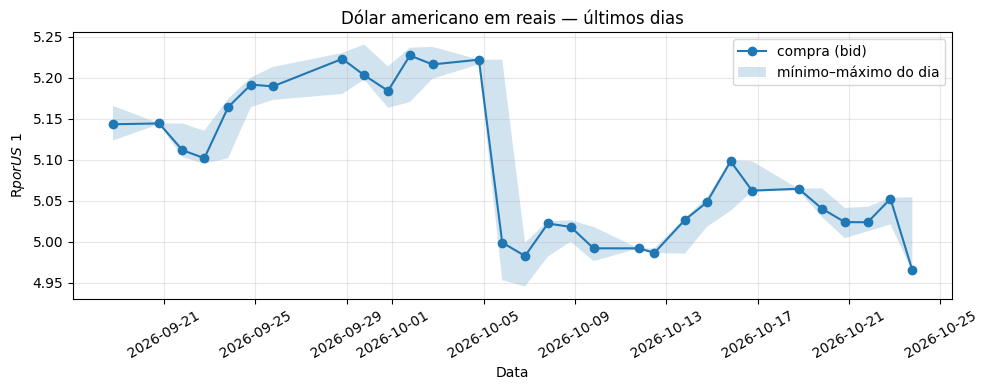

In [74]:
plt.figure(figsize=(10, 4))
plt.plot(df_hist["data"], df_hist["bid"], marker="o", label="compra (bid)")
plt.fill_between(df_hist["data"], df_hist["low"], df_hist["high"], alpha=0.2, label="mínimo–máximo do dia")
plt.title("Dólar americano em reais — últimos dias")
plt.xlabel("Data")
plt.ylabel("R$ por US$ 1")
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 6.4 Um período específico: parâmetros na URL

Para escolher as datas, a documentação usa os parâmetros `start_date` e `end_date` no formato **AAAAMMDD**.
Em vez de montar o texto `?start_date=...&end_date=...` à mão, passamos um **dicionário** em `params` e o `requests` monta a URL:

In [75]:
parametros = {"start_date": "20240701", "end_date": "20240731"}

print(f"Aguarde...")
resposta = requests.get(f"{BASE_URL}/json/daily/EUR-BRL/31{TOKEN}", params=parametros, timeout=TIMEOUT)
resposta.raise_for_status()

euro_julho = resposta.json()
print("Registros recebidos:", len(euro_julho))

Aguarde...
Registros recebidos: 31


### ✍️ Sua vez

Transforme `euro_julho` em um DataFrame (como na Parte 6.2) e faça o gráfico do euro em julho de 2024.

In [ ]:
# Sua vez

---
# Parte 7 — Mini-projeto: conversor de moedas

## 7.1 A ideia

Se 1 dólar vale `bid` reais, então:

- **dólar → real:** `valor_em_reais = valor_em_dolares × bid`
- **real → dólar:** `valor_em_dolares = valor_em_reais ÷ bid`

Vamos escrever uma função que aceita **qualquer par** que a API conheça:

In [78]:
def converter(valor, de, para, cotacoes=None):
    # Converte 'valor' da moeda 'de' para a moeda 'para' usando a cotação de compra (bid).
    # Se 'cotacoes' for informado, usa esses dados em vez de consultar a API.
    de, para = de.upper(), para.upper()
    if de == para:
        return valor

    par = f"{de}-{para}"
    chave = par.replace("-", "")

    if cotacoes is None:
        print(f"Aguarde...")
        cotacoes = obter_cotacoes([par])

    if chave not in cotacoes:
        raise RuntimeError(f"Cotação {par} não disponível nos dados.")

    taxa = float(cotacoes[chave]["bid"])
    return valor * taxa

In [79]:
for valor, de, para in [(100, "USD", "BRL"), (100, "EUR", "BRL"), (1, "BTC", "BRL"), (50, "USD", "EUR")]:
    try:
        convertido = converter(valor, de, para)
        print(f"{valor:>8,.2f} {de} = {convertido:>14,.2f} {para}")
    except RuntimeError as erro:
        print(f"{valor} {de} → {para}: {erro}")

Aguarde...
  100.00 USD =         496.52 BRL
Aguarde...
  100.00 EUR =         556.17 BRL
Aguarde...
    1.00 BTC =     404,111.00 BRL
Aguarde...
   50.00 USD =          44.63 EUR


Também podemos usar os dados do **Plano B**, sem acessar a internet:

In [80]:
print(f"100 USD = {converter(100, 'USD', 'BRL', cotacoes=COTACOES_EXEMPLO):,.2f} BRL (em 09/07/2024)")

100 USD = 544.62 BRL (em 09/07/2024)


> 🤔 **Pare e pense:** usamos o `bid` (compra). Se você quisesse **comprar** dólares para uma viagem, qual valor seria mais realista: `bid` ou `ask`? E a casa de câmbio cobraria exatamente isso?

## 7.2 Convertendo "por tabela"

E se a API não tiver o par direto que você quer? Podemos passar por uma moeda intermediária (o real):

$$\text{USD} \rightarrow \text{EUR} = \frac{\text{USD-BRL}}{\text{EUR-BRL}}$$

In [82]:
print(f"Aguarde...")
dados_tabela = obter_cotacoes(["USD-BRL", "EUR-BRL"])
usd_brl = float(dados_tabela["USDBRL"]["bid"])
eur_brl = float(dados_tabela["EURBRL"]["bid"])

print(f"1 USD = {usd_brl / eur_brl:.4f} EUR (calculado via BRL)")

Aguarde...
1 USD = 0.8927 EUR (calculado via BRL)


> 🤔 **Pare e pense:** compare com o resultado de `converter(1, "USD", "EUR")`. Os valores são iguais? Por que podem ser um pouco diferentes?

---
# Parte 8 — ✍️ Exercícios

**Exercício 1.** Busque de uma só vez as cotações de `GBP-BRL`, `JPY-BRL` e `ARS-BRL` e mostre, para cada uma, o nome e o valor de compra com 4 casas decimais.

In [ ]:
# Exercício 1

**Exercício 2.** Usando `df_cotacoes` (Parte 4.3), descubra qual moeda teve a **maior variação percentual** no dia (positiva ou negativa).

*Dica:* `df["pctChange"].abs().idxmax()`.

In [ ]:
# Exercício 2

**Exercício 3.** Escreva uma função `cotacao_hoje(par)` que devolva uma frase como:
`"Dólar Americano/Real Brasileiro: compra R$ 5,4462 em 09/07/2024 às 10:24"` (com vírgula decimal, no padrão brasileiro).

In [ ]:
# Exercício 3

**Exercício 4.** Busque os últimos **90 dias** do Bitcoin (`BTC-BRL`) e faça um gráfico. Compare a variação percentual no período com a do dólar.

In [ ]:
# Exercício 4

**Exercício 5.** Para o histórico do dólar (`df_hist`), crie a coluna `amplitude = high - low` e descubra o dia de **maior oscilação**.

In [ ]:
# Exercício 5

**Exercício 6.** Crie um **conversor interativo**: peça ao usuário o valor, a moeda de origem e a de destino com `input()`, e mostre o resultado. Trate os erros (valor não numérico, moeda inexistente) com mensagens amigáveis.

In [ ]:
# Exercício 6

**Exercício 7.** Salve o histórico do dólar em um arquivo CSV (`df_hist.to_csv("dolar.csv", index=False)`) e, em seguida, leia-o de volta com `pd.read_csv`. Por que guardar os dados localmente pode ser útil ao trabalhar com uma API com limite de uso?

In [ ]:
# Exercício 7

**Exercício 8 (desafio).** Compare o dólar **comercial** (`USD-BRL`) com o dólar **turismo** (`USD-BRLT`), segundo a documentação. Qual a diferença percentual entre eles? Por que o turismo é mais caro?

In [ ]:
# Exercício 8

**Exercício 9 (desafio).** A API devolve os dados também em **XML** (`/xml/USD-BRL/1`). Faça a requisição, mostre `resposta.text` e compare com o JSON. Qual formato é mais fácil de usar em Python? Por quê?

In [ ]:
# Exercício 9

---
# 📌 Resumo dos comandos

| Objetivo | Código |
|---|---|
| Fazer uma requisição | `r = requests.get(url, timeout=10)` |
| Verificar o status | `r.status_code`, `r.raise_for_status()` |
| Converter JSON → Python | `dados = r.json()` |
| Mostrar JSON organizado | `print(json.dumps(dados, indent=2, ensure_ascii=False))` |
| Navegar em dicionários aninhados | `dados["USDBRL"]["bid"]` |
| Percorrer um dicionário | `for chave, valor in dados.items():` |
| Juntar uma lista em texto | `",".join(["USD-BRL", "EUR-BRL"])` |
| Parâmetros na URL | `requests.get(url, params={"start_date": "20240701"})` |
| Cabeçalho com chave de API | `requests.get(url, headers={"x-api-key": chave})` |
| Texto → número | `float("5.4462")` |
| Timestamp → data | `datetime.fromtimestamp(ts, tz=timezone.utc)` |
| Dicionário de dicionários → tabela | `pd.DataFrame.from_dict(dados, orient="index")` |
| Lista de dicionários → tabela | `pd.DataFrame(lista)` |

## 🎓 Boas práticas ao consumir APIs

1. **Leia a documentação** antes de programar: ela é o "cardápio".
2. Use sempre **`timeout`** e verifique o **status** da resposta.
3. **Converta os tipos**: APIs frequentemente enviam números como texto.
4. **Trate os erros** e mostre mensagens úteis ao usuário.
5. **Respeite os limites** do serviço: agrupe pedidos (várias moedas em uma requisição) e guarde dados localmente quando possível.
6. **Nunca exponha chaves de API** no código compartilhado.
7. Desconfie da **estrutura** dos dados: campos podem faltar em alguns registros.

## 📚 Referências

- Documentação da API de cotações: https://docs.awesomeapi.com.br/api-de-moedas
- Instruções para chave de API: https://docs.awesomeapi.com.br/instrucoes-api-key
- Documentação do `requests`: https://requests.readthedocs.io/
- Módulo `json`: https://docs.python.org/pt-br/3/library/json.html
- Módulo `datetime`: https://docs.python.org/pt-br/3/library/datetime.html
- Códigos de moedas ISO 4217: https://pt.wikipedia.org/wiki/ISO_4217